# 04. 카운트형 노드 피처의 시간 드리프트 — 누적 창 vs 고정 창, 일자 기준

서비스(v10)는 노드 피처를 **데이터 시작일부터 전체 누적**으로 계산한다. 카운트형 피처는 시간이 갈수록 단조 증가하므로
"계좌 성격"이 아니라 "달력"을 담을 수 있다. 이 노트북은 그게 실제로 문제인지를 잰다:

> **기준일마다 세탁 vs 정상의 피처 분리력(단변량 AUC)이 일정하게 유지되는가? 고정 창(90일)으로 바꾸면 달라지는가?**

02 를 여러 번 돌리는 대신, 02 `node_agg` 와 **같은 SQL 정의**로 카운트형 8개만 기준일마다 직접 계산한다.

| 피처 (02 이름) | 원시값 | 정의 |
|---|---|---|
| log_out_count / log_in_count | out_n / in_n | 송금 / 수취 건수 |
| log_out_neighbors / log_in_neighbors | out_u / in_u | 서로 다른 수신 / 송신 노드 수 |
| log_active_days | n_days | 송금 또는 수취가 있었던 날짜 수 |
| log_entity_observed_accounts | observed_entity_accounts | 같은 entity_id 로 창 안에서 활동한 계좌 수 |
| log_entity_out_diversity / log_entity_in_diversity | ent_out_n / ent_in_n | 엔티티가 송금한 / 수취한 서로 다른 상대 엔티티 수 |

**기준일(eval day)**: `DAY_START` 부터 `DAY_STEP` 일 간격 (기본 7일) — 고정 창은 매일 내용이 바뀌므로 월말 스냅샷으로는 부족하다.
**창(variant)**: `cumulative` = 데이터 시작~기준일 (서비스와 동일), `w30`/`w60` = 기준일 뒤로 30/60일 슬라이딩. `VARIANTS` 로 바꿀 수 있다.
(HI-Large 는 정상 거래가 있는 구간이 ~96일이라 90일 창은 누적과 구분이 안 된다. 짧은 창으로 "창을 자르면 신호가 어떻게 변하나"를 보고, 배포용 창 길이(패턴 지속시간 p95 기준)는 그 추세로 외삽한다.)
**미래 참조 없음**: 기준일 D 의 피처는 D 까지의 거래로만 계산하고, 엣지 수준(7절)은 **D 당일 거래**만 평가한다 — 서비스의 당일 마감 추론과 같은 형태.
(이전 버전은 월말 피처를 그 달 전체 거래에 붙여서 최대 30일 미래 참조가 있었다. 그 결과는 `node_drift.json` 에 남아 있다.)

**라벨**: 노드 수준 = 기준일에 활동한 계좌 중 그날 세탁 거래에 관여한 계좌. 엣지 수준 = 기준일 거래의 라벨.

출력: `parquets/<DATASET>/analysis/node_drift_<TAG>.json`, `node_drift_*_<TAG>.png`. 그림 라벨은 영어(GPU 에 한글 폰트 없음).

## 0. 설정

In [1]:
!pip install --break-system-packages --no-cache-dir -q duckdb pyarrow matplotlib

In [2]:
from pathlib import Path
import json, time
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt

DATASET = "HI-Large"
VARIANTS = {"cumulative": None, "w30": 30, "w60": 60}   # 이름 → 창 길이(일). None 이면 데이터 시작부터 누적 (서비스와 동일)
                                              # 사용 가능 구간이 ~96일이라 w90 은 누적과 거의 같다 → 짧은 창(30·60)으로 "창 길이에 따른 신호 변화"를 본다
DAY_START, DAY_MAX = None, "2022-11-14"       # 기준일 범위. None 이면 데이터 처음/끝. HI-Large 는 11월 중순 이후 정상 거래가 없어 DAY_MAX 로 끊는다
DAY_STEP = 7                                  # 기준일 간격(일). 1 이면 매일 (Large 는 하루당 ~2분 × variant 수)
EVAL_DAYS = None                              # 직접 지정하면 위 세 개 무시. 예: ["2022-09-01", "2022-09-02", "2022-10-31"]
WARMUP_DAYS = 28                              # 요약(6절)에서 '첫 기준일'은 데이터 시작 후 이 일수가 지난 첫 기준일 (시작 직후 왜곡 제외)
EDGE_SAMPLE_PER_DAY = 300_000                 # 7절: 기준일 라벨0 거래 표본 수 (라벨1 은 전부)
RUN_EDGE_LEVEL = True
TAG = "daily"                                 # 결과 파일 접미사 (이전 월말 버전 node_drift.json 과 구분)
THREADS, MEMORY, WORK_DIR = 4, "6GB", None   # Large 는 8 / "24GB" 이상 권장

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "datasets").is_dir())
BASE = ROOT / "parquets" / DATASET
OUT = BASE / "analysis"; OUT.mkdir(parents=True, exist_ok=True)
assert (BASE / "transactions.parquet").is_file() and (BASE / "kyc.parquet").is_file(), "01 먼저 실행"
q = lambda v: "'" + str(v).replace("'", "''") + "'"
suffix = f"_{TAG}" if TAG else ""
fig_path = lambda name: OUT / f"node_drift_{name}{suffix}.png"

work = (Path(WORK_DIR) if WORK_DIR else OUT) / "work_node_drift.duckdb"
for stale in (work, Path(str(work) + ".wal")): stale.unlink(missing_ok=True)
con = duckdb.connect(str(work))
con.execute(f"SET threads={THREADS}"); con.execute(f"SET memory_limit='{MEMORY}'"); con.execute("SET preserve_insertion_order=false")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
C_NORMAL, C_LAUND = "#8da0cb", "#e15759"
# 원시값 → 02 피처 이름, 엣지 수준에서 어느 쪽 노드를 볼지
FEATURES = {"out_n": ("log_out_count", "src"), "in_n": ("log_in_count", "dst"),
            "out_u": ("log_out_neighbors", "src"), "in_u": ("log_in_neighbors", "dst"),
            "n_days": ("log_active_days", "src"), "observed_entity_accounts": ("log_entity_observed_accounts", "src"),
            "ent_out_n": ("log_entity_out_diversity", "src"), "ent_in_n": ("log_entity_in_diversity", "dst")}
NAMES = [v[0] for v in FEATURES.values()]
result = dict(dataset=DATASET, variants=VARIANTS, features=NAMES, day_step=DAY_STEP, warmup_days=WARMUP_DAYS)
print(ROOT, "\n", OUT)

/workspace/money_laundry_ai_ 
 /workspace/money_laundry_ai_/parquets/HI-Large/analysis


## 1. 입력 `tx`, `kyc`, 기준일 목록

02 와 같은 필터(중복 대표만). `tx` 에 양쪽 entity_id 를 미리 붙여 둔다 (02 `hist` 뷰의 `source_entity/target_entity`).
기준일은 `DAY_START` 부터 `DAY_STEP` 간격, `DAY_MAX` 까지 (데이터 마지막 날은 항상 포함하지 않는다 — 꼬리 구간은 믿을 수 없다).

In [3]:
t0 = time.perf_counter()
con.execute(f"CREATE OR REPLACE TABLE kyc AS SELECT node_id, entity_id FROM read_parquet({q(BASE/'kyc.parquet')})")
con.execute(f"""
    CREATE OR REPLACE TABLE tx AS
    SELECT t.edge_id, t.day, t.src, t.dst, t.is_laundering, ks.entity_id AS src_entity, kd.entity_id AS dst_entity
    FROM read_parquet({q(BASE/'transactions.parquet')}) t
    JOIN kyc ks ON ks.node_id = t.src JOIN kyc kd ON kd.node_id = t.dst
    WHERE t.duplicate_group_id IS NULL OR t.edge_id = t.duplicate_group_id""")
n, n_l, d0, d1 = con.execute("SELECT count(*), sum(is_laundering::INT), min(day), max(day) FROM tx").fetchone()
if EVAL_DAYS is None:
    start = pd.Timestamp(DAY_START or d0); stop = pd.Timestamp(DAY_MAX or d1)
    EVAL_DAYS = [str(d.date()) for d in pd.date_range(start, stop, freq=f"{DAY_STEP}D")]
result.update(rows=n, laundering=n_l, day_min=str(d0), day_max=str(d1), eval_days=EVAL_DAYS)
print(f"거래 {n:,}  라벨1 {n_l:,}  기간 {d0} ~ {d1}   ({time.perf_counter()-t0:.0f}s)")
print(f"기준일 {len(EVAL_DAYS)}개: {EVAL_DAYS[0]} ~ {EVAL_DAYS[-1]} ({DAY_STEP}일 간격)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

거래 179,702,079  라벨1 225,546  기간 2022-08-01 ~ 2023-01-12   (55s)
기준일 16개: 2022-08-01 ~ 2022-11-14 (7일 간격)


## 2. 기준일별 거래·계좌 수와 라벨 `day_nodes`

먼저 **일별 거래 수(정상/세탁)** 를 전체 기간에 대해 찍어서 데이터가 실제로 어디서 끝나는지 본다 (HI-Large 는 11월 중순 이후 세탁 꼬리만 남는다).
`day_nodes` = 기준일에 활동한(송금 또는 수취) 계좌와 그날 세탁 거래 관여 여부. 활동 안 한 계좌는 그날 평가에서 제외.

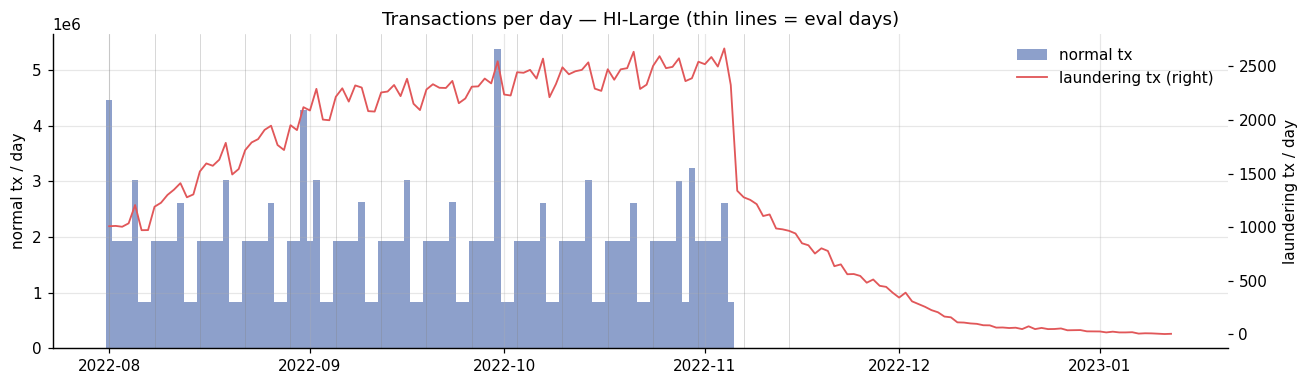

정상 거래가 중앙값의 절반 이상인 마지막 날: 2022-11-05 00:00:00  → DAY_MAX 는 이 날 이전이어야 한다 (현재 2022-11-14)


,eval_day,active_nodes,laundering_nodes,rate
0,2022-08-01 00:00:00,"1,752,226","1,620.0",0.092%
1,2022-08-08 00:00:00,"899,311","2,015.0",0.224%
2,2022-08-15 00:00:00,"899,910","2,589.0",0.288%
3,2022-08-22 00:00:00,"899,250","2,970.0",0.330%
4,2022-08-29 00:00:00,"898,509","3,358.0",0.374%
5,2022-09-05 00:00:00,"901,070","3,764.0",0.418%
6,2022-09-12 00:00:00,"901,824","3,897.0",0.432%
7,2022-09-19 00:00:00,"900,544","3,981.0",0.442%
8,2022-09-26 00:00:00,"901,058","4,046.0",0.449%
9,2022-10-03 00:00:00,"900,667","4,253.0",0.472%


In [4]:
daily = con.execute("SELECT day, count(*) AS tx, sum(is_laundering::INT) AS laund_tx FROM tx GROUP BY 1 ORDER BY 1").df()
daily["laund_rate"] = daily.laund_tx / daily.tx
result["daily_tx"] = daily.astype({"day": str}).to_dict("records")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(daily.day, daily.tx - daily.laund_tx, color=C_NORMAL, width=1, label="normal tx")
ax2 = ax.twinx(); ax2.plot(daily.day, daily.laund_tx, color=C_LAUND, lw=1.2, label="laundering tx (right)"); ax2.grid(False)
for d in EVAL_DAYS: ax.axvline(pd.Timestamp(d), color="gray", lw=0.4, alpha=0.5)
ax.set_ylabel("normal tx / day"); ax2.set_ylabel("laundering tx / day"); ax.set_title(f"Transactions per day — {DATASET} (thin lines = eval days)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(fig_path("0_tx_per_day"), bbox_inches="tight"); plt.show()
last_full = daily[daily.tx - daily.laund_tx > 0.5 * (daily.tx - daily.laund_tx).median()].day.max()
print(f"정상 거래가 중앙값의 절반 이상인 마지막 날: {last_full}  → DAY_MAX 는 이 날 이전이어야 한다 (현재 {EVAL_DAYS[-1]})")

con.execute("CREATE OR REPLACE TABLE day_nodes (eval_day DATE, node_id BIGINT, laund BOOLEAN)")
for d in EVAL_DAYS:
    con.execute(f"""
        INSERT INTO day_nodes
        SELECT DATE {q(d)}, node_id, bool_or(is_laundering)
        FROM (SELECT src AS node_id, is_laundering FROM tx WHERE day = DATE {q(d)} UNION ALL SELECT dst, is_laundering FROM tx WHERE day = DATE {q(d)})
        GROUP BY node_id""")
dn = con.execute("SELECT eval_day, count(*) AS active_nodes, sum(laund::INT) AS laundering_nodes, avg(laund::INT) AS rate FROM day_nodes GROUP BY 1 ORDER BY 1").df()
result["day_nodes"] = dn.astype({"eval_day": str}).to_dict("records")
dn.style.format({"active_nodes": "{:,}", "laundering_nodes": "{:,}", "rate": "{:.3%}"})

## 3. 기준일마다 카운트형 노드 피처 계산 `nf`

`node_counts(end, window_days)` 는 02 `node_agg` 의 해당 CTE 를 그대로 쓴다 (`hist` → `WHERE day <= end [AND day > end − W]`).
`observed_entity_accounts` 는 02 처럼 "창 안에서 활동한(`active_days` 에 있는) 같은 entity 의 계좌 수".
variant × 기준일 만큼 전체 스캔이 돈다 — Large 는 한 번에 1~2분. 2 variant × 15 기준일이면 한 시간 안팎.

In [5]:
def node_counts(end, window_days):
    lower = f"AND day > DATE {q(end)} - INTERVAL {window_days} DAY" if window_days else ""
    return f"""
    WITH h AS (SELECT * FROM tx WHERE day <= DATE {q(end)} {lower}),
         outgoing AS (SELECT src AS node_id, count(*) AS out_n, count(DISTINCT dst) AS out_u FROM h GROUP BY src),
         incoming AS (SELECT dst AS node_id, count(*) AS in_n, count(DISTINCT src) AS in_u FROM h GROUP BY dst),
         active AS (SELECT src AS node_id, day FROM h UNION SELECT dst, day FROM h),
         active_days AS (SELECT node_id, count(*) AS n_days FROM active GROUP BY node_id),
         ent_pairs AS (SELECT DISTINCT src_entity, dst_entity FROM h WHERE src_entity IS NOT NULL AND dst_entity IS NOT NULL),
         ent_out AS (SELECT src_entity AS entity_id, count(*) AS ent_out_n FROM ent_pairs GROUP BY 1),
         ent_in  AS (SELECT dst_entity AS entity_id, count(*) AS ent_in_n  FROM ent_pairs GROUP BY 1)
    SELECT k.node_id,
           coalesce(o.out_n,0) AS out_n, coalesce(i.in_n,0) AS in_n, coalesce(o.out_u,0) AS out_u, coalesce(i.in_u,0) AS in_u, ad.n_days,
           CASE WHEN k.entity_id IS NULL THEN 0 ELSE count(*) OVER (PARTITION BY k.entity_id) END AS observed_entity_accounts,
           coalesce(eo.ent_out_n,0) AS ent_out_n, coalesce(ei.ent_in_n,0) AS ent_in_n
    FROM active_days ad JOIN kyc k USING (node_id) LEFT JOIN outgoing o USING (node_id) LEFT JOIN incoming i USING (node_id)
    LEFT JOIN ent_out eo ON k.entity_id = eo.entity_id LEFT JOIN ent_in ei ON k.entity_id = ei.entity_id"""

con.execute("DROP TABLE IF EXISTS nf")
con.execute("""CREATE TABLE nf (variant VARCHAR, eval_day DATE, node_id BIGINT, out_n BIGINT, in_n BIGINT, out_u BIGINT, in_u BIGINT,
                                n_days BIGINT, observed_entity_accounts BIGINT, ent_out_n BIGINT, ent_in_n BIGINT)""")
timing = {}
for variant, w in VARIANTS.items():
    for d in EVAL_DAYS:
        t0 = time.perf_counter()
        con.execute(f"INSERT INTO nf SELECT {q(variant)}, DATE {q(d)}, * FROM ({node_counts(d, w)})")
        timing[f"{variant}@{d}"] = round(time.perf_counter() - t0, 1)
        print(f"{variant:11s} {d}  {timing[f'{variant}@{d}']:6.0f}s", flush=True)
result["timing_sec"] = timing
con.execute("SELECT variant, eval_day, count(*) AS nodes, avg(out_n) AS mean_out_n, max(out_n) AS max_out_n FROM nf GROUP BY 1, 2 ORDER BY 1, 2").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

cumulative  2022-08-01       3s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

cumulative  2022-08-08       6s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

w60         2022-11-07      54s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

w60         2022-11-14      44s


,variant,eval_day,nodes,mean_out_n,max_out_n
0,cumulative,2022-08-01,1752226,2.549227,88327
1,cumulative,2022-08-08,2063587,8.170908,538661
2,cumulative,2022-08-15,2075841,13.901856,973904
3,cumulative,2022-08-22,2083793,19.797487,1424239
4,cumulative,2022-08-29,2089043,25.488966,1859482
5,cumulative,2022-09-05,2096320,32.444944,2325764
6,cumulative,2022-09-12,2098590,38.134901,2761007
7,cumulative,2022-09-19,2100031,44.014278,3211342
8,cumulative,2022-09-26,2101035,49.706774,3646585
9,cumulative,2022-10-03,2108939,56.521206,4112869


## 4. 지표 계산 함수 — 단변량 AUC, 분위수

AUC 는 Mann–Whitney: 값에 평균 순위를 매겨 `(Σrank(양성) − n₊(n₊+1)/2) / (n₊·n₋)`. 0.5 면 구분 못 함, 1 이면 완벽.
0.5 아래면 "값이 작을수록 세탁" 방향. 분리력은 `|AUC − 0.5|`. 양성 또는 음성이 없는 그룹은 NaN.
분위수는 모델 입력과 같은 `ln(1+x)` 스케일.

In [6]:
def auc_table(data_sql, group_cols, feat_expr, label_col="y"):
    """data_sql 의 각 group_cols 그룹에서 feat_expr 의 단변량 AUC·분위수. feat_expr 는 원시값(ln 변환은 여기서)."""
    g = ", ".join(group_cols)
    return con.execute(f"""
        WITH d AS (SELECT {g}, {label_col} AS y, ln(1 + {feat_expr}) AS v FROM ({data_sql})),
             r AS (SELECT *, rank() OVER (PARTITION BY {g} ORDER BY v) + (count(*) OVER (PARTITION BY {g}, v) - 1) / 2.0 AS rk FROM d)
        SELECT {g},
               count(*) FILTER (WHERE y) AS n_pos, count(*) FILTER (WHERE NOT y) AS n_neg,
               CASE WHEN count(*) FILTER (WHERE y) = 0 OR count(*) FILTER (WHERE NOT y) = 0 THEN NULL ELSE
               (sum(rk) FILTER (WHERE y) - count(*) FILTER (WHERE y) * (count(*) FILTER (WHERE y) + 1) / 2.0)
                 / (count(*) FILTER (WHERE y) * count(*) FILTER (WHERE NOT y)) END AS auc,
               quantile_cont(v, 0.5) FILTER (WHERE y) AS med_pos, quantile_cont(v, 0.5) FILTER (WHERE NOT y) AS med_neg,
               quantile_cont(v, 0.25) FILTER (WHERE y) AS p25_pos, quantile_cont(v, 0.75) FILTER (WHERE y) AS p75_pos,
               quantile_cont(v, 0.25) FILTER (WHERE NOT y) AS p25_neg, quantile_cont(v, 0.75) FILTER (WHERE NOT y) AS p75_neg
        FROM r GROUP BY {g} ORDER BY {g}""").df()

def auc_plot(df, title, ylabel, fname):
    """variant 별 패널, 피처별 선, x = 기준일"""
    fig, axes = plt.subplots(1, len(VARIANTS), figsize=(6.8 * len(VARIANTS), 4.2), sharey=True, squeeze=False)
    for ax, variant in zip(axes[0], VARIANTS):
        sub = df[df.variant == variant]
        for name in NAMES:
            s = sub[sub.feature == name].sort_values("eval_day"); ax.plot(pd.to_datetime(s.eval_day), s.auc, marker="o", ms=3, label=name)
        ax.axhline(0.5, color="gray", ls="--", lw=1); ax.set_title(f"{title} — {variant}"); ax.tick_params(axis="x", rotation=30)
    axes[0][0].set_ylabel(ylabel); axes[0][-1].legend(fontsize=7, frameon=False, loc="best")
    fig.tight_layout(); fig.savefig(fig_path(fname), bbox_inches="tight"); plt.show()

## 5. 노드 수준 — 기준일별 AUC·분위수

기준일에 활동한 계좌 전체. 표는 행=기준일, 열=피처.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

105s


feature,log_out_count,log_in_count,log_out_neighbors,log_in_neighbors,log_active_days,log_entity_observed_accounts,log_entity_out_diversity,log_entity_in_diversity
eval_day,,,,,,,,
2022-08-01,0.638,0.701,0.657,0.715,0.500,0.410,0.477,0.463
2022-08-08,0.486,0.407,0.546,0.562,0.325,0.542,0.573,0.546
2022-08-15,0.496,0.406,0.571,0.569,0.336,0.544,0.586,0.556
2022-08-22,0.513,0.399,0.601,0.578,0.336,0.545,0.596,0.570
2022-08-29,0.520,0.385,0.616,0.571,0.332,0.557,0.606,0.578
2022-09-05,0.513,0.386,0.625,0.580,0.343,0.551,0.603,0.579
2022-09-12,0.512,0.379,0.637,0.590,0.336,0.560,0.610,0.590
2022-09-19,0.513,0.379,0.642,0.592,0.330,0.554,0.609,0.585
2022-09-26,0.516,0.373,0.653,0.586,0.325,0.558,0.611,0.590


feature,log_out_count,log_in_count,log_out_neighbors,log_in_neighbors,log_active_days,log_entity_observed_accounts,log_entity_out_diversity,log_entity_in_diversity
eval_day,,,,,,,,
2022-08-01,0.638,0.701,0.657,0.715,0.500,0.410,0.477,0.463
2022-08-08,0.486,0.407,0.546,0.562,0.325,0.542,0.573,0.546
2022-08-15,0.496,0.406,0.571,0.569,0.336,0.544,0.586,0.556
2022-08-22,0.513,0.399,0.601,0.578,0.336,0.545,0.596,0.570
2022-08-29,0.520,0.385,0.616,0.571,0.332,0.557,0.606,0.578
2022-09-05,0.523,0.391,0.617,0.578,0.343,0.552,0.603,0.579
2022-09-12,0.521,0.387,0.620,0.584,0.336,0.560,0.609,0.589
2022-09-19,0.520,0.388,0.618,0.592,0.330,0.554,0.609,0.586
2022-09-26,0.521,0.384,0.624,0.584,0.326,0.558,0.611,0.591


feature,log_out_count,log_in_count,log_out_neighbors,log_in_neighbors,log_active_days,log_entity_observed_accounts,log_entity_out_diversity,log_entity_in_diversity
eval_day,,,,,,,,
2022-08-01,0.638,0.701,0.657,0.715,0.500,0.410,0.477,0.463
2022-08-08,0.486,0.407,0.546,0.562,0.325,0.542,0.573,0.546
2022-08-15,0.496,0.406,0.571,0.569,0.336,0.544,0.586,0.556
2022-08-22,0.513,0.399,0.601,0.578,0.336,0.545,0.596,0.570
2022-08-29,0.520,0.385,0.616,0.571,0.332,0.557,0.606,0.578
2022-09-05,0.513,0.386,0.625,0.580,0.343,0.551,0.603,0.579
2022-09-12,0.512,0.379,0.637,0.590,0.336,0.560,0.610,0.590
2022-09-19,0.513,0.379,0.642,0.592,0.330,0.554,0.609,0.585
2022-09-26,0.516,0.373,0.653,0.586,0.325,0.558,0.611,0.590


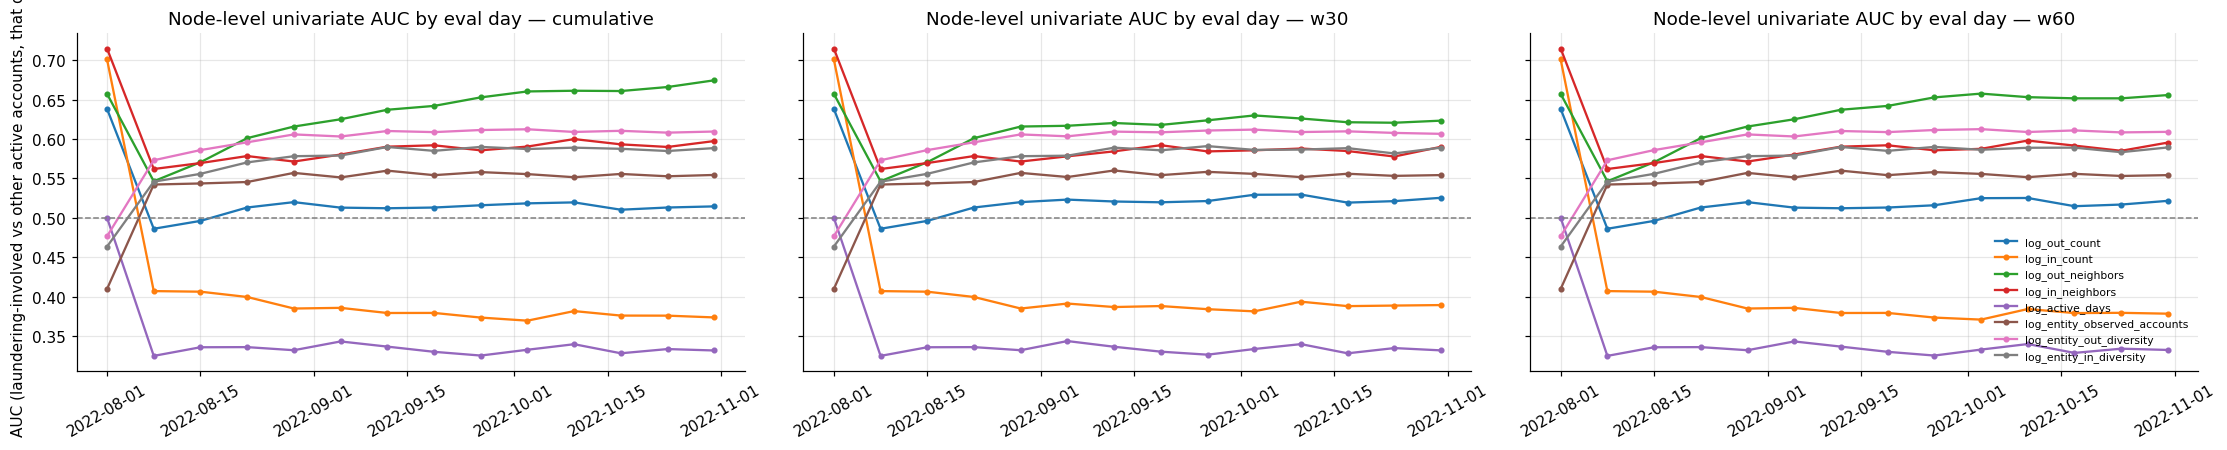

In [7]:
t0 = time.perf_counter()
frames = []
for raw, (name, _) in FEATURES.items():
    d = auc_table(f"SELECT f.variant, f.eval_day, f.{raw} AS val, m.laund AS y FROM nf f JOIN day_nodes m USING (eval_day, node_id)",
                  ["variant", "eval_day"], "val")
    d.insert(0, "feature", name); frames.append(d)
node_auc = pd.concat(frames, ignore_index=True)
node_auc["auc_abs"] = (node_auc.auc - 0.5).abs(); node_auc["eval_day"] = node_auc.eval_day.astype(str)
result["node_level"] = node_auc.round(5).to_dict("records")
print(f"{time.perf_counter()-t0:.0f}s")
for variant in VARIANTS:
    pv = node_auc[node_auc.variant == variant].pivot(index="eval_day", columns="feature", values="auc")[NAMES]
    display(pv.style.format("{:.3f}", na_rep="–").background_gradient(cmap="RdBu_r", vmin=0.2, vmax=0.8, axis=None).set_caption(f"node-level AUC by eval day — {variant}"))
auc_plot(node_auc, "Node-level univariate AUC by eval day", "AUC (laundering-involved vs other active accounts, that day)", "A_node_auc")

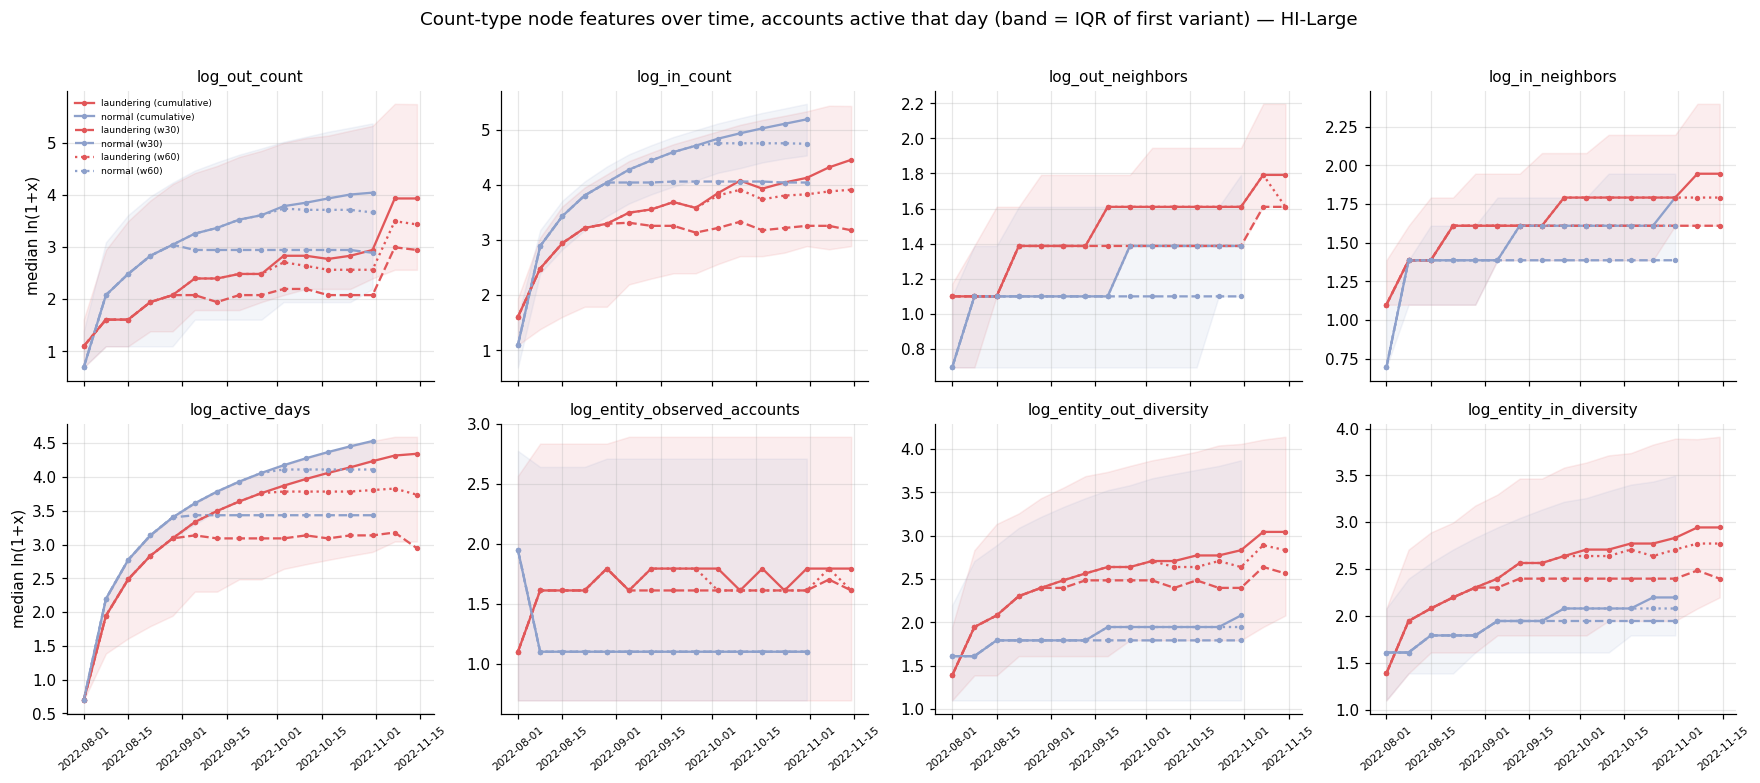

In [8]:
# 그림 B: 피처별 중앙값(ln 스케일) 추이 — 세탁 vs 정상, 누적(실선) vs 고정창(점선)
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
styles = dict(zip(VARIANTS, ["-", "--", ":", "-."]))
for ax, name in zip(axes.ravel(), NAMES):
    for variant in VARIANTS:
        s = node_auc[(node_auc.variant == variant) & (node_auc.feature == name)].sort_values("eval_day"); x = pd.to_datetime(s.eval_day)
        ax.plot(x, s.med_pos, styles[variant], color=C_LAUND, marker="o", ms=2.5, label=f"laundering ({variant})")
        ax.plot(x, s.med_neg, styles[variant], color=C_NORMAL, marker="o", ms=2.5, label=f"normal ({variant})")
        if variant == list(VARIANTS)[0]:
            ax.fill_between(x, s.p25_pos, s.p75_pos, color=C_LAUND, alpha=0.10); ax.fill_between(x, s.p25_neg, s.p75_neg, color=C_NORMAL, alpha=0.10)
    ax.set_title(name, fontsize=10); ax.tick_params(axis="x", rotation=40, labelsize=7)
axes[0][0].set_ylabel("median ln(1+x)"); axes[1][0].set_ylabel("median ln(1+x)"); axes[0][0].legend(fontsize=6, frameon=False)
fig.suptitle(f"Count-type node features over time, accounts active that day (band = IQR of first variant) — {DATASET}", y=1.01)
fig.tight_layout(); fig.savefig(fig_path("B_median"), bbox_inches="tight"); plt.show()

## 6. 요약 — 워밍업 이후 첫 기준일 vs 마지막 유효 기준일, 누적 vs 고정 창

`first` = 데이터 시작 후 `WARMUP_DAYS` 가 지난 첫 기준일(시작 직후 왜곡 제외), `last` = AUC 가 계산된 마지막 기준일.
`Δ` = last − first 의 `|AUC−0.5|`. 음수면 뒤로 갈수록 분리력이 줄어든 것. `w90 − cumulative` 가 양수면 고정 창이 더 잘 가른다.
`slope` = 기준일 전체에 대한 `|AUC−0.5|` 의 선형 추세 (30일당 변화) — 점 하나 비교보다 안정적.

In [9]:
def summarize(df, label):
    valid = df.dropna(subset=["auc"])
    days = sorted(valid.eval_day.unique())
    first = next((d for d in days if (pd.Timestamp(d) - pd.Timestamp(result["day_min"])).days >= WARMUP_DAYS), days[0]); last = days[-1]
    rows = []
    for name in NAMES:
        r = {"feature": name}
        for variant in VARIANTS:
            s = valid[(valid.variant == variant) & (valid.feature == name)].set_index("eval_day").sort_index()
            if first in s.index and last in s.index:
                r[f"{variant}_first"] = s.loc[first, "auc_abs"]; r[f"{variant}_last"] = s.loc[last, "auc_abs"]; r[f"{variant}_Δ"] = r[f"{variant}_last"] - r[f"{variant}_first"]
            t = (pd.to_datetime(s.index) - pd.Timestamp(first)).days.values / 30.0; y = s.auc_abs.values; m = t >= 0
            r[f"{variant}_slope/30d"] = np.polyfit(t[m], y[m], 1)[0] if m.sum() >= 3 else np.nan
        if len(VARIANTS) >= 2:
            a, b = list(VARIANTS)[:2]; r[f"{b}−{a} (last)"] = r.get(f"{b}_last", np.nan) - r.get(f"{a}_last", np.nan)
        rows.append(r)
    out = pd.DataFrame(rows).set_index("feature")
    print(f"[{label}] first = {first}, last = {last}")
    return out, first, last
summary_node, first_day, last_day = summarize(node_auc, "node-level")
result["node_level_summary"] = summary_node.round(5).to_dict("index"); result["summary_first_day"], result["summary_last_day"] = first_day, last_day
summary_node.style.format("{:+.3f}", na_rep="–").background_gradient(cmap="RdBu", vmin=-0.1, vmax=0.1, subset=[c for c in summary_node.columns if "Δ" in c or "−" in c or "slope" in c])

[node-level] first = 2022-08-29, last = 2022-10-31


,cumulative_first,cumulative_last,cumulative_Δ,cumulative_slope/30d,w30_first,w30_last,w30_Δ,w30_slope/30d,w60_first,w60_last,w60_Δ,w60_slope/30d,w30−cumulative (last)
feature,,,,,,,,,,,,,
log_out_count,+0.020,+0.014,-0.005,-0.001,+0.020,+0.025,+0.006,+0.002,+0.020,+0.022,+0.002,+0.003,+0.011
log_in_count,+0.115,+0.127,+0.011,+0.005,+0.115,+0.111,-0.004,-0.001,+0.115,+0.122,+0.007,+0.002,-0.016
log_out_neighbors,+0.116,+0.175,+0.059,+0.026,+0.116,+0.123,+0.007,+0.003,+0.116,+0.156,+0.040,+0.017,-0.051
log_in_neighbors,+0.071,+0.097,+0.026,+0.009,+0.071,+0.090,+0.019,+0.004,+0.071,+0.096,+0.024,+0.007,-0.007
log_active_days,+0.168,+0.169,+0.000,+0.002,+0.168,+0.168,+0.000,+0.002,+0.168,+0.168,-0.000,+0.002,-0.000
log_entity_observed_accounts,+0.057,+0.054,-0.003,-0.001,+0.057,+0.054,-0.003,-0.001,+0.057,+0.054,-0.003,-0.001,-0.000
log_entity_out_diversity,+0.106,+0.110,+0.004,+0.002,+0.106,+0.107,+0.001,+0.001,+0.106,+0.109,+0.003,+0.002,-0.003
log_entity_in_diversity,+0.078,+0.088,+0.010,+0.003,+0.078,+0.089,+0.011,+0.003,+0.078,+0.089,+0.011,+0.003,+0.001


## 7. 거래(엣지) 수준 — 모델이 보는 형태, 미래 참조 없음

기준일 **당일 거래**마다 송신 노드(out·entity 계열) 또는 수신 노드(in 계열)의 **그날 기준** 피처값을 붙이고, 거래 라벨에 대한 AUC.
라벨1 거래는 전부, 라벨0 은 기준일마다 `EDGE_SAMPLE_PER_DAY` 건 표본. 노드 수준과 결론이 다르면 이쪽을 우선한다.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

39s


feature,log_out_count,log_in_count,log_out_neighbors,log_in_neighbors,log_active_days,log_entity_observed_accounts,log_entity_out_diversity,log_entity_in_diversity
eval_day,,,,,,,,
2022-08-01,0.622,0.615,0.683,0.718,0.500,0.476,0.550,0.647
2022-08-08,0.328,0.266,0.459,0.605,0.322,0.520,0.491,0.707
2022-08-15,0.300,0.262,0.458,0.615,0.329,0.514,0.499,0.705
2022-08-22,0.261,0.254,0.458,0.620,0.301,0.520,0.504,0.706
2022-08-29,0.268,0.245,0.477,0.604,0.297,0.530,0.524,0.704
2022-09-05,0.271,0.250,0.486,0.624,0.311,0.533,0.530,0.701
2022-09-12,0.242,0.230,0.475,0.628,0.300,0.532,0.524,0.711
2022-09-19,0.253,0.226,0.487,0.617,0.292,0.528,0.525,0.708
2022-09-26,0.255,0.231,0.502,0.614,0.291,0.537,0.539,0.710


feature,log_out_count,log_in_count,log_out_neighbors,log_in_neighbors,log_active_days,log_entity_observed_accounts,log_entity_out_diversity,log_entity_in_diversity
eval_day,,,,,,,,
2022-08-01,0.622,0.615,0.683,0.718,0.500,0.476,0.550,0.647
2022-08-08,0.328,0.266,0.459,0.605,0.322,0.520,0.491,0.707
2022-08-15,0.300,0.262,0.458,0.615,0.329,0.514,0.499,0.705
2022-08-22,0.261,0.254,0.458,0.620,0.301,0.520,0.504,0.706
2022-08-29,0.268,0.245,0.477,0.604,0.297,0.530,0.524,0.704
2022-09-05,0.273,0.254,0.479,0.623,0.312,0.533,0.528,0.703
2022-09-12,0.244,0.238,0.460,0.625,0.300,0.532,0.519,0.712
2022-09-19,0.256,0.234,0.464,0.626,0.293,0.528,0.519,0.711
2022-09-26,0.258,0.242,0.472,0.627,0.292,0.538,0.530,0.716


feature,log_out_count,log_in_count,log_out_neighbors,log_in_neighbors,log_active_days,log_entity_observed_accounts,log_entity_out_diversity,log_entity_in_diversity
eval_day,,,,,,,,
2022-08-01,0.622,0.615,0.683,0.718,0.500,0.476,0.550,0.647
2022-08-08,0.328,0.266,0.459,0.605,0.322,0.520,0.491,0.707
2022-08-15,0.300,0.262,0.458,0.615,0.329,0.514,0.499,0.705
2022-08-22,0.261,0.254,0.458,0.620,0.301,0.520,0.504,0.706
2022-08-29,0.268,0.245,0.477,0.604,0.297,0.530,0.524,0.704
2022-09-05,0.271,0.250,0.486,0.624,0.311,0.533,0.530,0.701
2022-09-12,0.242,0.230,0.475,0.628,0.300,0.532,0.524,0.711
2022-09-19,0.253,0.226,0.487,0.617,0.292,0.528,0.525,0.708
2022-09-26,0.255,0.231,0.502,0.614,0.291,0.537,0.539,0.710


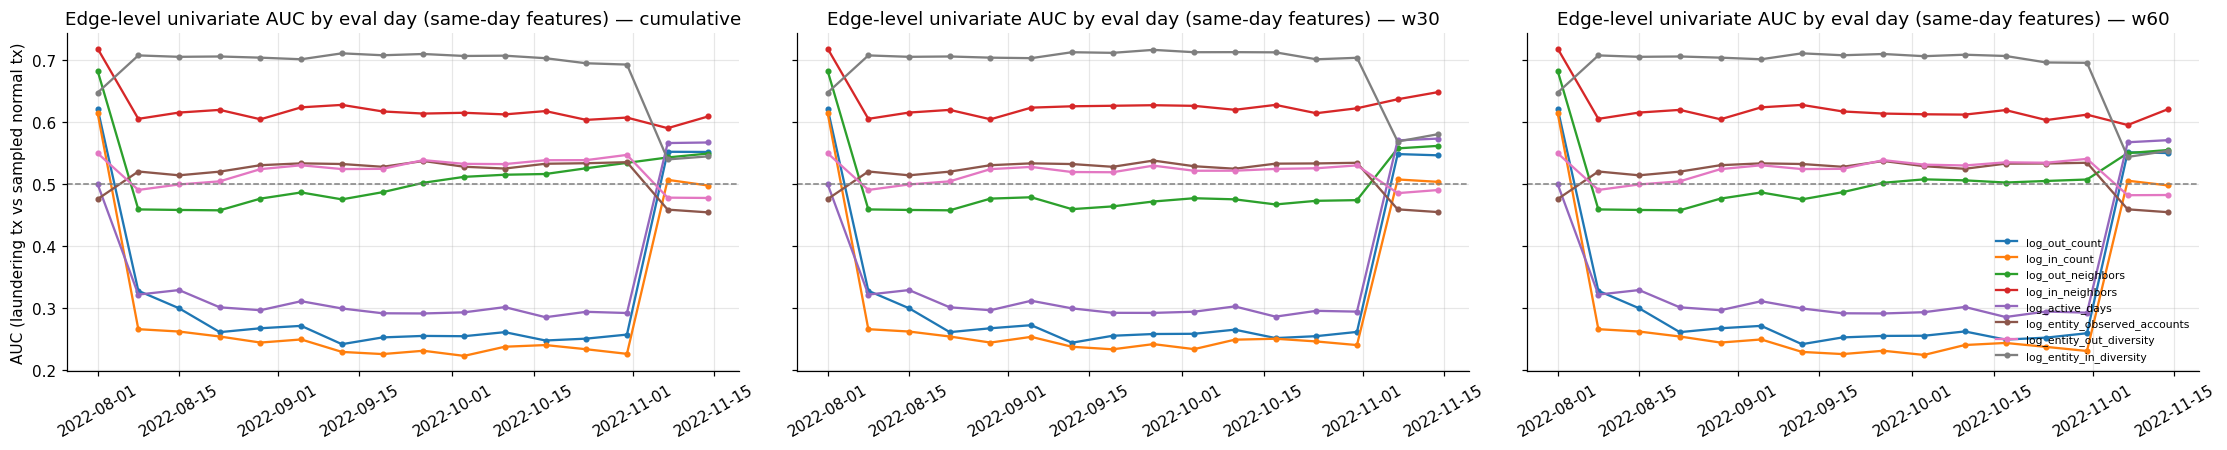

[edge-level] first = 2022-08-29, last = 2022-11-14


,cumulative_first,cumulative_last,cumulative_Δ,cumulative_slope/30d,w30_first,w30_last,w30_Δ,w30_slope/30d,w60_first,w60_last,w60_Δ,w60_slope/30d,w30−cumulative (last)
feature,,,,,,,,,,,,,
log_out_count,+0.232,+0.052,-0.181,-0.055,+0.232,+0.046,-0.186,-0.056,+0.232,+0.050,-0.182,-0.056,-0.005
log_in_count,+0.255,+0.002,-0.253,-0.075,+0.255,+0.004,-0.252,-0.076,+0.255,+0.002,-0.253,-0.077,+0.001
log_out_neighbors,+0.023,+0.049,+0.026,+0.011,+0.023,+0.062,+0.038,+0.009,+0.023,+0.055,+0.031,+0.008,+0.012
log_in_neighbors,+0.104,+0.109,+0.005,-0.007,+0.104,+0.148,+0.044,+0.008,+0.104,+0.121,+0.017,-0.004,+0.039
log_active_days,+0.203,+0.067,-0.136,-0.038,+0.203,+0.073,-0.130,-0.037,+0.203,+0.071,-0.132,-0.038,+0.006
log_entity_observed_accounts,+0.030,+0.046,+0.015,+0.004,+0.030,+0.045,+0.015,+0.004,+0.030,+0.045,+0.015,+0.004,-0.000
log_entity_out_diversity,+0.024,+0.022,-0.002,+0.002,+0.024,+0.010,-0.015,-0.003,+0.024,+0.018,-0.006,-0.000,-0.013
log_entity_in_diversity,+0.204,+0.045,-0.159,-0.051,+0.204,+0.080,-0.123,-0.040,+0.204,+0.054,-0.150,-0.049,+0.036


In [10]:
if RUN_EDGE_LEVEL:
    t0 = time.perf_counter()
    con.execute("DROP TABLE IF EXISTS edge_smp")
    con.execute("CREATE TABLE edge_smp (eval_day DATE, edge_id BIGINT, src BIGINT, dst BIGINT, y BOOLEAN)")
    for d in EVAL_DAYS:
        n_norm = con.execute(f"SELECT count(*) FROM tx WHERE NOT is_laundering AND day = DATE {q(d)}").fetchone()[0]
        p = min(1.0, EDGE_SAMPLE_PER_DAY / max(n_norm, 1))
        con.execute(f"""INSERT INTO edge_smp SELECT DATE {q(d)}, edge_id, src, dst, is_laundering FROM tx
                        WHERE day = DATE {q(d)} AND (is_laundering OR random() < {p})""")
    frames = []
    for raw, (name, side) in FEATURES.items():
        d = auc_table(f"""SELECT f.variant, s.eval_day, f.{raw} AS val, s.y
                          FROM edge_smp s JOIN nf f ON f.eval_day = s.eval_day AND f.node_id = s.{side}""", ["variant", "eval_day"], "val")
        d.insert(0, "feature", name); d.insert(1, "node_side", side); frames.append(d)
    edge_auc = pd.concat(frames, ignore_index=True)
    edge_auc["auc_abs"] = (edge_auc.auc - 0.5).abs(); edge_auc["eval_day"] = edge_auc.eval_day.astype(str)
    result["edge_level"] = edge_auc.round(5).to_dict("records")
    print(f"{time.perf_counter()-t0:.0f}s")
    display(edge_auc[edge_auc.feature == NAMES[0]].pivot(index="eval_day", columns="variant", values=["n_pos", "n_neg"]).style.format("{:,.0f}").set_caption("edge sample size per eval day"))
    for variant in VARIANTS:
        pv = edge_auc[edge_auc.variant == variant].pivot(index="eval_day", columns="feature", values="auc")[NAMES]
        display(pv.style.format("{:.3f}", na_rep="–").background_gradient(cmap="RdBu_r", vmin=0.2, vmax=0.8, axis=None).set_caption(f"edge-level AUC by eval day — {variant}"))
    auc_plot(edge_auc, "Edge-level univariate AUC by eval day (same-day features)", "AUC (laundering tx vs sampled normal tx)", "C_edge_auc")
    summary_edge, _, _ = summarize(edge_auc, "edge-level")
    result["edge_level_summary"] = summary_edge.round(5).to_dict("index")
    display(summary_edge.style.format("{:+.3f}", na_rep="–").background_gradient(cmap="RdBu", vmin=-0.1, vmax=0.1, subset=[c for c in summary_edge.columns if "Δ" in c or "−" in c or "slope" in c]).set_caption("edge-level summary"))
else:
    edge_auc = None; print("RUN_EDGE_LEVEL=False — 7절 건너뜀")

## 8. 마무리 — `analysis/node_drift_<TAG>.json`, 작업 파일 정리

In [11]:
con.close()
for stale in (work, Path(str(work) + ".wal")): stale.unlink(missing_ok=True)
(OUT / f"node_drift{suffix}.json").write_text(json.dumps(result, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("node-level:\n" + summary_node.round(3).to_string())
if edge_auc is not None: print("\nedge-level:\n" + summary_edge.round(3).to_string())
for f in sorted(OUT.glob(f"node_drift*{suffix}.*")): print(f"{f.name:44s} {f.stat().st_size/1e3:8.1f} KB")

node-level:
                              cumulative_first  cumulative_last  cumulative_Δ  cumulative_slope/30d  w30_first  w30_last  w30_Δ  w30_slope/30d  w60_first  w60_last  w60_Δ  w60_slope/30d  w30−cumulative (last)
feature                                                                                                                                                                                                         
log_out_count                            0.020            0.014        -0.005                -0.001      0.020     0.025  0.006          0.002      0.020     0.022  0.002          0.003                  0.011
log_in_count                             0.115            0.127         0.011                 0.005      0.115     0.111 -0.004         -0.001      0.115     0.122  0.007          0.002                 -0.016
log_out_neighbors                        0.116            0.175         0.059                 0.026      0.116     0.123  0.007          0.003      0.11

## 읽는 법 / 다음 결정

- **2절 일별 거래 그림**: 정상 거래가 끊기는 날을 먼저 확인. `DAY_MAX` 가 그 전이어야 하고, 학습·검증·테스트 분할도 그 날을 넘기면 안 된다 (그 뒤는 세탁 꼬리만 남아 "날짜 = 세탁"이 된다).
- **그림 A / C**: 피처별 AUC 선이 평평하면 누적 창이어도 분리력이 유지되는 것. 0.5 쪽으로 기울면 누적이 신호를 희석한다. 7일 간격이라 월말 허브 유입 같은 주기 효과도 보인다.
- **그림 B**: 정상 계좌 중앙값이 매주 올라가는 건 누적 창의 당연한 모양. 중요한 건 빨강(세탁)과 파랑(정상) **사이 간격**. 점선(w90)은 데이터 시작 90일 뒤부터 평평해져야 정상.
- **6절·7절 요약표**: `cumulative_slope/30d` 가 −0.02 아래이고 `w90 − cumulative` 가 양수면 → 고정 창 전환 근거. 전부 ±0.01 안이면 데이터셋 기간 안에선 누적 그대로 둬도 됨.
  단, HI-Large 는 활동 구간이 ~3.5개월이라 w90 과 cumulative 가 거의 같다 — **이 데이터로 두 창의 우열을 가르긴 어렵고**, 서비스용 고정 창은 운영 기간(1년+) 관점에서 결정한다.
- **5절과 7절의 방향이 반대로 나올 수 있다** (예: `log_out_count` 노드 >0.5, 엣지 <0.5). 모순이 아니라 정상 *거래*의 대부분이 초대형 허브 계좌에서 나오기 때문. 모델은 거래를 분류하므로 7절이 기준.
- 결론이 "고정 창"이면 02 를 `WINDOW_DAYS=90, TAG="w90"` 로 돌려 19개 노드 피처 전체를 만들고, 학습·서비스(`preprocess.py` 의 `prepare_snapshot` 하한) 를 **같이** 바꿔야 한다.